#Step 1: Environment setup

In [ ]:
# Check GPU availability
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

CUDA available: True
Device: Tesla T4


In [ ]:
# Installing required packages
!pip install -q torch torchvision scikit-learn matplotlib seaborn

#Step 2:Getting the CIFAKE dataset

In [ ]:
# Mounting at Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Verifying the structure of the dataset
import os

dataset_root = '/content/cifake'

for root, dirs, filenames in os.walk(dataset_root):
    level = root.replace(dataset_root, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/  ({len(filenames)} files)')
    if level >= 2:
        continue

cifake/  (0 files)
  test/  (0 files)
    REAL/  (10000 files)
    FAKE/  (10000 files)
  train/  (0 files)
    REAL/  (50000 files)
    FAKE/  (50000 files)


#Step 3 : Building the Dataset and visualizing samples

In [ ]:
import torchvision
from torchvision import transforms

# Basic transform: resize (CIFAKE images are already 32x32) and convert to tensor
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = torchvision.datasets.ImageFolder(root='/content/cifake/train', transform=transform)
test_dataset = torchvision.datasets.ImageFolder(root='/content/cifake/test', transform=transform)

print("Classes:", train_dataset.classes)
print("Class-to-index mapping:", train_dataset.class_to_idx)
print("Train size:", len(train_dataset))
print("Test size:", len(test_dataset))

Classes: ['FAKE', 'REAL']
Class-to-index mapping: {'FAKE': 0, 'REAL': 1}
Train size: 100000
Test size: 20000


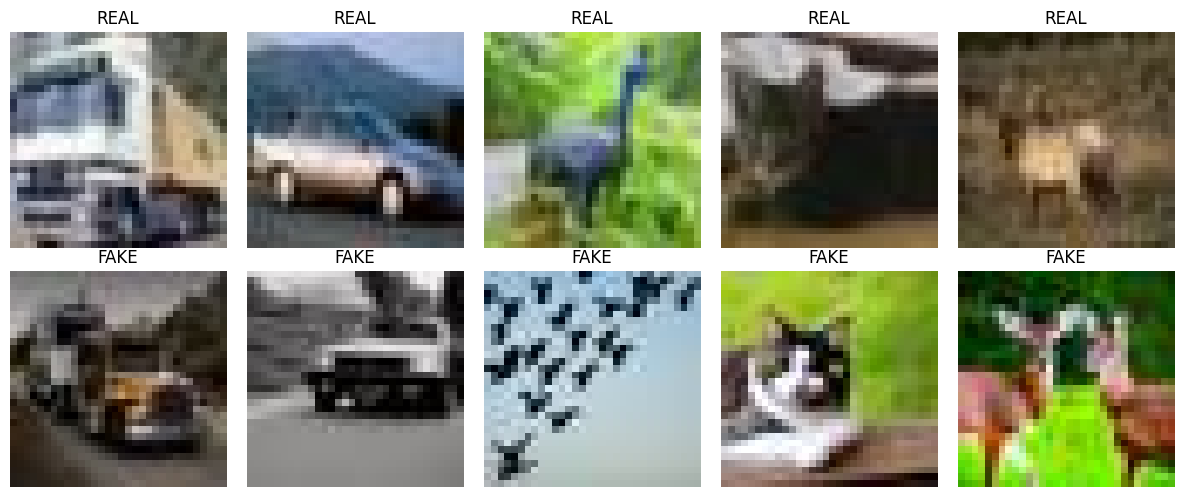

In [ ]:
import matplotlib.pyplot as plt

# Visualize a few samples from each class
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

real_indices = [i for i, (_, label) in enumerate(train_dataset.samples) if label == train_dataset.class_to_idx['REAL']][:5]
fake_indices = [i for i, (_, label) in enumerate(train_dataset.samples) if label == train_dataset.class_to_idx['FAKE']][:5]

for col, idx in enumerate(real_indices):
    img, label = train_dataset[idx]
    axes[0, col].imshow(img.permute(1, 2, 0))
    axes[0, col].set_title("REAL")
    axes[0, col].axis('off')

for col, idx in enumerate(fake_indices):
    img, label = train_dataset[idx]
    axes[1, col].imshow(img.permute(1, 2, 0))
    axes[1, col].set_title("FAKE")
    axes[1, col].axis('off')

plt.tight_layout()
plt.show()

#Step 4: Building the CNN model and training loop

In [ ]:
from torch.utils.data import DataLoader, random_split

# Split train_dataset into train/validation (90/10)
train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_subset, val_subset = random_split(train_dataset, [train_size, val_size])

batch_size = 128
train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}")

Train batches: 704, Val batches: 79, Test batches: 157


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)   # 32x32 -> 32x32
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)  # 16x16 -> 16x16
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1) # 8x8 -> 8x8
        self.pool = nn.MaxPool2d(2, 2)                            # halves spatial size each time
        self.dropout = nn.Dropout(0.3)
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 2)  # 2 output classes: FAKE, REAL

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # 32x32 -> 16x16
        x = self.pool(F.relu(self.conv2(x)))  # 16x16 -> 8x8
        x = self.pool(F.relu(self.conv3(x)))  # 8x8 -> 4x4
        x = x.view(x.size(0), -1)             # flatten
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = SimpleCNN().to(device)
print(model)

SimpleCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=2, bias=True)
)


#Step 5: Training loop

In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 10

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

In [ ]:
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

In [ ]:
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

Epoch 1/10 | Train Loss: 0.3078, Train Acc: 0.8641 | Val Loss: 0.2146, Val Acc: 0.9147
Epoch 2/10 | Train Loss: 0.1945, Train Acc: 0.9233 | Val Loss: 0.2974, Val Acc: 0.8819
Epoch 3/10 | Train Loss: 0.1696, Train Acc: 0.9344 | Val Loss: 0.1722, Val Acc: 0.9353
Epoch 4/10 | Train Loss: 0.1485, Train Acc: 0.9427 | Val Loss: 0.1588, Val Acc: 0.9355
Epoch 5/10 | Train Loss: 0.1342, Train Acc: 0.9483 | Val Loss: 0.1609, Val Acc: 0.9377
Epoch 6/10 | Train Loss: 0.1202, Train Acc: 0.9538 | Val Loss: 0.1451, Val Acc: 0.9452
Epoch 7/10 | Train Loss: 0.1096, Train Acc: 0.9580 | Val Loss: 0.1456, Val Acc: 0.9439
Epoch 8/10 | Train Loss: 0.0996, Train Acc: 0.9622 | Val Loss: 0.1559, Val Acc: 0.9389
Epoch 9/10 | Train Loss: 0.0891, Train Acc: 0.9657 | Val Loss: 0.1654, Val Acc: 0.9371
Epoch 10/10 | Train Loss: 0.0817, Train Acc: 0.9689 | Val Loss: 0.1464, Val Acc: 0.9470


#Step 6: Plot learning curves + evaluate on test set

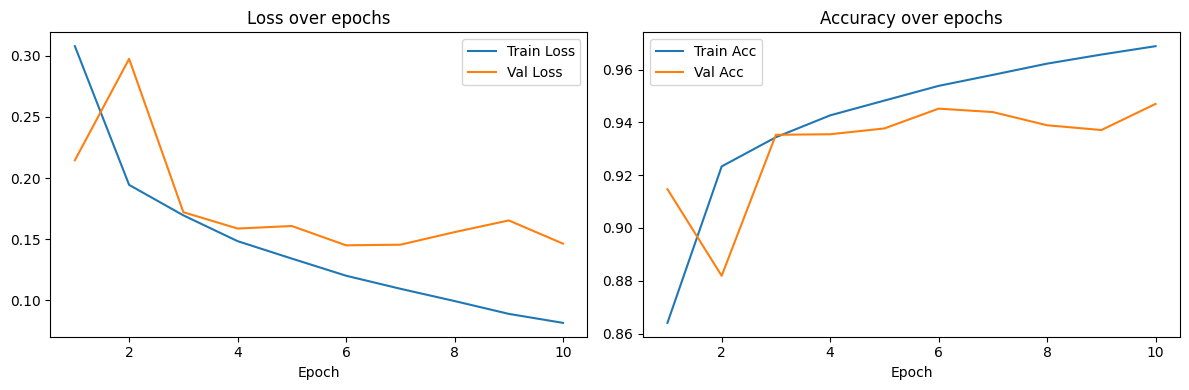

In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, num_epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history['train_loss'], label='Train Loss')
axes[0].plot(epochs_range, history['val_loss'], label='Val Loss')
axes[0].set_title('Loss over epochs')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(epochs_range, history['train_acc'], label='Train Acc')
axes[1].plot(epochs_range, history['val_acc'], label='Val Acc')
axes[1].set_title('Accuracy over epochs')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Final evaluation on the untouched test set
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

Test Loss: 0.1555, Test Accuracy: 0.9442


#Step 7: Confusion matrix + precision/recall/F1

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

In [ ]:
cm = confusion_matrix(all_labels, all_preds)
print("Confusion Matrix:")
print(cm)
print("\nClass mapping:", train_dataset.class_to_idx)

Confusion Matrix:
[[9689  311]
 [ 805 9195]]

Class mapping: {'FAKE': 0, 'REAL': 1}


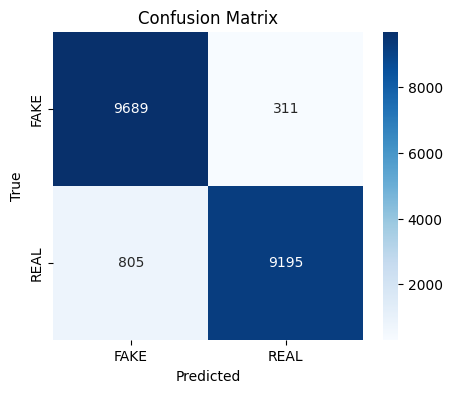

In [ ]:
import seaborn as sns

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['FAKE', 'REAL'], yticklabels=['FAKE', 'REAL'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
print(classification_report(all_labels, all_preds, target_names=['FAKE', 'REAL']))

              precision    recall  f1-score   support

        FAKE       0.92      0.97      0.95     10000
        REAL       0.97      0.92      0.94     10000

    accuracy                           0.94     20000
   macro avg       0.95      0.94      0.94     20000
weighted avg       0.95      0.94      0.94     20000



#Step 8: Grad-CAM (interpretability)

In [ ]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 117.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np

# Grad-CAM needs a target convolutional layer — we use the last conv layer (conv3)
target_layers = [model.conv3]

cam = GradCAM(model=model, target_layers=target_layers)

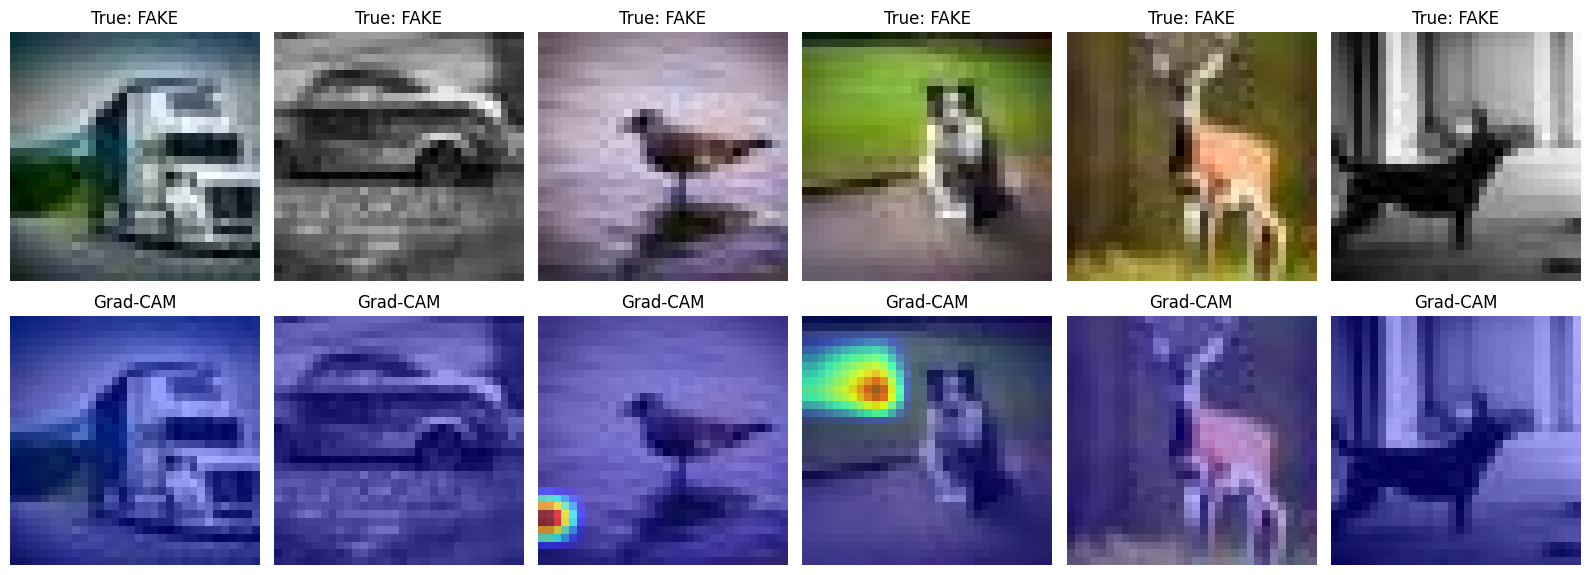

In [ ]:
# Grab a few test images to visualize
sample_images = []
sample_labels = []
for images, labels in test_loader:
    sample_images = images[:6]
    sample_labels = labels[:6]
    break

fig, axes = plt.subplots(2, 6, figsize=(16, 6))

for i in range(6):
    img_tensor = sample_images[i].unsqueeze(0).to(device)
    rgb_img = sample_images[i].permute(1, 2, 0).numpy()

    grayscale_cam = cam(input_tensor=img_tensor)[0]
    visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    true_label = train_dataset.classes[sample_labels[i]]

    axes[0, i].imshow(rgb_img)
    axes[0, i].set_title(f"True: {true_label}")
    axes[0, i].axis('off')

    axes[1, i].imshow(visualization)
    axes[1, i].set_title("Grad-CAM")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

#Step 9: Frequency-domain (FFT) feature enhancement

Step 9a: Visualizing the difference

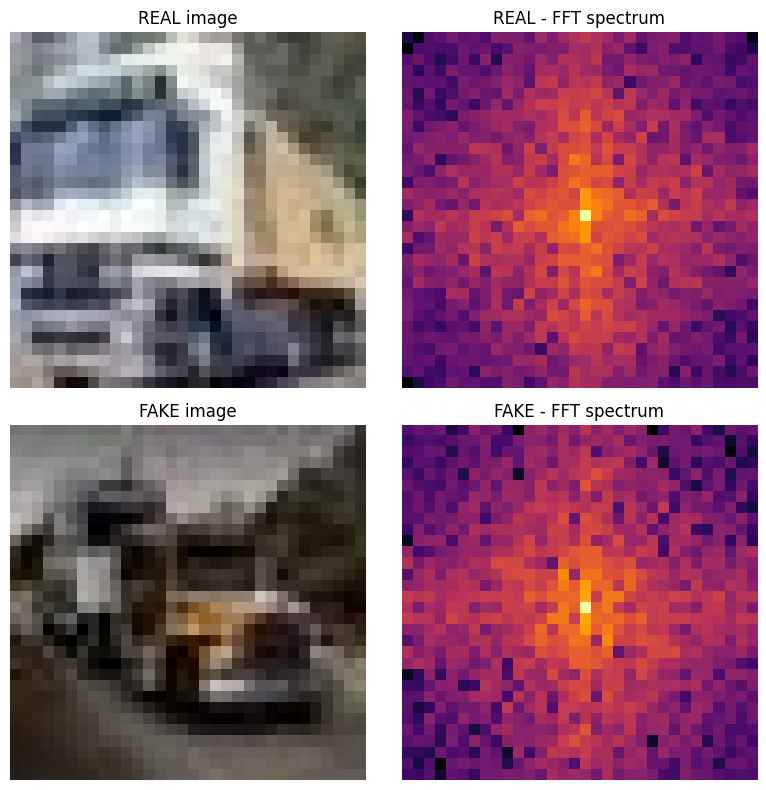

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def compute_fft_magnitude(img_tensor):
    """Takes a CxHxW tensor, returns log-magnitude FFT spectrum averaged across channels."""
    img_gray = img_tensor.mean(dim=0).numpy()  # average RGB -> grayscale
    f = np.fft.fft2(img_gray)
    fshift = np.fft.fftshift(f)  # move zero-frequency to center
    magnitude = np.log(np.abs(fshift) + 1e-8)  # log scale for visibility
    return magnitude

# Grab one REAL and one FAKE sample
real_idx = [i for i, (_, label) in enumerate(train_dataset.samples) if label == train_dataset.class_to_idx['REAL']][0]
fake_idx = [i for i, (_, label) in enumerate(train_dataset.samples) if label == train_dataset.class_to_idx['FAKE']][0]

real_img, _ = train_dataset[real_idx]
fake_img, _ = train_dataset[fake_idx]

real_fft = compute_fft_magnitude(real_img)
fake_fft = compute_fft_magnitude(fake_img)

fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes[0, 0].imshow(real_img.permute(1, 2, 0)); axes[0, 0].set_title("REAL image"); axes[0, 0].axis('off')
axes[0, 1].imshow(real_fft, cmap='inferno'); axes[0, 1].set_title("REAL - FFT spectrum"); axes[0, 1].axis('off')
axes[1, 0].imshow(fake_img.permute(1, 2, 0)); axes[1, 0].set_title("FAKE image"); axes[1, 0].axis('off')
axes[1, 1].imshow(fake_fft, cmap='inferno'); axes[1, 1].set_title("FAKE - FFT spectrum"); axes[1, 1].axis('off')
plt.tight_layout()
plt.show()

Step 9b: Average FFT spectrum across many samples

In [ ]:
import numpy as np

def average_fft_spectrum(dataset, class_idx, n_samples=1000):
    """Averages log-magnitude FFT spectra over n_samples images of a given class."""
    indices = [i for i, (_, label) in enumerate(dataset.samples) if label == class_idx][:n_samples]

    accumulated = None
    for idx in indices:
        img, _ = dataset[idx]
        img_gray = img.mean(dim=0).numpy()
        f = np.fft.fft2(img_gray)
        fshift = np.fft.fftshift(f)
        magnitude = np.log(np.abs(fshift) + 1e-8)

        if accumulated is None:
            accumulated = magnitude
        else:
            accumulated += magnitude

    return accumulated / len(indices)

real_avg_fft = average_fft_spectrum(train_dataset, train_dataset.class_to_idx['REAL'], n_samples=1000)
fake_avg_fft = average_fft_spectrum(train_dataset, train_dataset.class_to_idx['FAKE'], n_samples=1000)

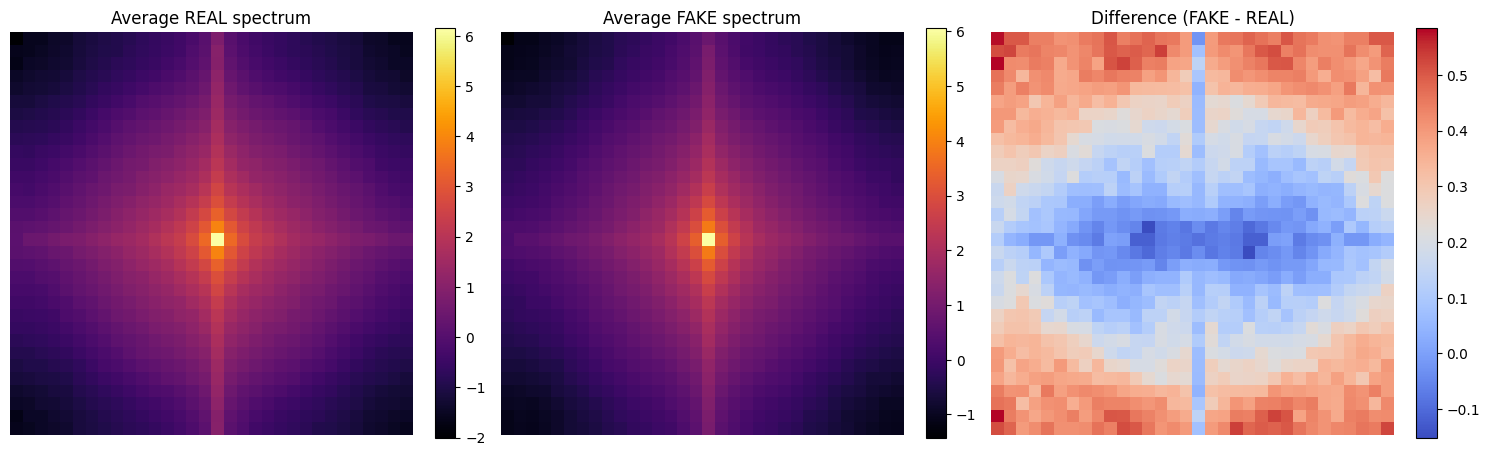

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

im0 = axes[0].imshow(real_avg_fft, cmap='inferno')
axes[0].set_title('Average REAL spectrum')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(fake_avg_fft, cmap='inferno')
axes[1].set_title('Average FAKE spectrum')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], fraction=0.046)

diff = fake_avg_fft - real_avg_fft
im2 = axes[2].imshow(diff, cmap='coolwarm')
axes[2].set_title('Difference (FAKE - REAL)')
axes[2].axis('off')
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

#Step 10: Build the dual-input model (RGB + FFT magnitude)

Step 10a: Custom Dataset that returns both the image and its FFT

In [ ]:
from torch.utils.data import Dataset
from PIL import Image
import numpy as np
import torch

class FFTImageDataset(Dataset):
    def __init__(self, image_folder_dataset):
        self.base_dataset = image_folder_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        img, label = self.base_dataset[idx]  # img is a CxHxW tensor (already ToTensor'd)

        # Compute FFT magnitude from grayscale version
        img_gray = img.mean(dim=0).numpy()
        f = np.fft.fft2(img_gray)
        fshift = np.fft.fftshift(f)
        magnitude = np.log(np.abs(fshift) + 1e-8)

        # Normalize FFT magnitude to roughly [0, 1] for stable training
        magnitude = (magnitude - magnitude.min()) / (magnitude.max() - magnitude.min() + 1e-8)
        fft_tensor = torch.tensor(magnitude, dtype=torch.float32).unsqueeze(0)  # add channel dim -> 1xHxW

        return img, fft_tensor, label

In [ ]:
train_fft_dataset = FFTImageDataset(train_subset)
val_fft_dataset = FFTImageDataset(val_subset)
test_fft_dataset = FFTImageDataset(test_dataset)

train_fft_loader = DataLoader(train_fft_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_fft_loader = DataLoader(val_fft_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_fft_loader = DataLoader(test_fft_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

Step 10b: The dual-branch model

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class DualBranchCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # RGB branch
        self.rgb_conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.rgb_conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.rgb_conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        # FFT branch (single channel input)
        self.fft_conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.fft_conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.fft_conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.3)

        # After 3 pools: 32x32 -> 4x4, so flattened size = 128 * 4 * 4 per branch
        self.fc1 = nn.Linear(128 * 4 * 4 * 2, 256)  # *2 because we concatenate both branches
        self.fc2 = nn.Linear(256, 2)

    def forward(self, rgb, fft):
        # RGB branch
        r = self.pool(F.relu(self.rgb_conv1(rgb)))
        r = self.pool(F.relu(self.rgb_conv2(r)))
        r = self.pool(F.relu(self.rgb_conv3(r)))
        r = r.view(r.size(0), -1)

        # FFT branch
        f = self.pool(F.relu(self.fft_conv1(fft)))
        f = self.pool(F.relu(self.fft_conv2(f)))
        f = self.pool(F.relu(self.fft_conv3(f)))
        f = f.view(f.size(0), -1)

        # Fuse both branches
        combined = torch.cat([r, f], dim=1)
        x = self.dropout(F.relu(self.fc1(combined)))
        x = self.fc2(x)
        return x

In [ ]:
model_dual = DualBranchCNN().to(device)
print(model_dual)

DualBranchCNN(
  (rgb_conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (rgb_conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (rgb_conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fft_conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fft_conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fft_conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=2, bias=True)
)


#Step 11: Training loop adapted for dual input

In [ ]:
criterion_dual = nn.CrossEntropyLoss()
optimizer_dual = optim.Adam(model_dual.parameters(), lr=0.001)
num_epochs = 10

In [ ]:
def train_one_epoch_dual(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for rgb, fft, labels in loader:
        rgb, fft, labels = rgb.to(device), fft.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(rgb, fft)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * rgb.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

In [ ]:
def evaluate_dual(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for rgb, fft, labels in loader:
            rgb, fft, labels = rgb.to(device), fft.to(device), labels.to(device)
            outputs = model(rgb, fft)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * rgb.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return running_loss / total, correct / total

In [ ]:
history_dual = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch_dual(model_dual, train_fft_loader, optimizer_dual, criterion_dual, device)
    val_loss, val_acc = evaluate_dual(model_dual, val_fft_loader, criterion_dual, device)

    history_dual['train_loss'].append(train_loss)
    history_dual['train_acc'].append(train_acc)
    history_dual['val_loss'].append(val_loss)
    history_dual['val_acc'].append(val_acc)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

Epoch 1/10 | Train Loss: 0.2798, Train Acc: 0.8774 | Val Loss: 0.1820, Val Acc: 0.9272
Epoch 2/10 | Train Loss: 0.1807, Train Acc: 0.9284 | Val Loss: 0.1603, Val Acc: 0.9374
Epoch 3/10 | Train Loss: 0.1542, Train Acc: 0.9395 | Val Loss: 0.1609, Val Acc: 0.9349
Epoch 4/10 | Train Loss: 0.1345, Train Acc: 0.9477 | Val Loss: 0.1860, Val Acc: 0.9286
Epoch 5/10 | Train Loss: 0.1210, Train Acc: 0.9529 | Val Loss: 0.1346, Val Acc: 0.9463
Epoch 6/10 | Train Loss: 0.1105, Train Acc: 0.9573 | Val Loss: 0.1199, Val Acc: 0.9541
Epoch 7/10 | Train Loss: 0.0965, Train Acc: 0.9624 | Val Loss: 0.1190, Val Acc: 0.9541
Epoch 8/10 | Train Loss: 0.0902, Train Acc: 0.9651 | Val Loss: 0.1242, Val Acc: 0.9540
Epoch 9/10 | Train Loss: 0.0784, Train Acc: 0.9700 | Val Loss: 0.1534, Val Acc: 0.9467
Epoch 10/10 | Train Loss: 0.0709, Train Acc: 0.9729 | Val Loss: 0.1352, Val Acc: 0.9537


In [ ]:
test_loss_dual, test_acc_dual = evaluate_dual(model_dual, test_fft_loader, criterion_dual, device)
print(f"Dual-branch Test Loss: {test_loss_dual:.4f}, Test Accuracy: {test_acc_dual:.4f}")

Dual-branch Test Loss: 0.1383, Test Accuracy: 0.9511


#Step 12: Inference/demo — predict on any uploaded image

Step 12a: Save the trained model

In [ ]:
import torch

# Save to Drive so it survives runtime disconnects
torch.save(model_dual.state_dict(), '/content/drive/MyDrive/pfa_dataset/dual_branch_model.pth')
print("Model saved to Drive.")

Model saved to Drive.


Step 12b: The inference function

In [ ]:
from PIL import Image
import torch.nn.functional as F
import numpy as np
import torchvision.transforms as transforms

def predict_image(image_path, model, device):
    # Load and preprocess the image
    img = Image.open(image_path).convert('RGB')
    img = img.resize((32, 32))  # match training resolution

    transform = transforms.ToTensor()
    img_tensor = transform(img)  # CxHxW, values in [0,1]

    # Compute FFT magnitude, same as during training
    img_gray = img_tensor.mean(dim=0).numpy()
    f = np.fft.fft2(img_gray)
    fshift = np.fft.fftshift(f)
    magnitude = np.log(np.abs(fshift) + 1e-8)
    magnitude = (magnitude - magnitude.min()) / (magnitude.max() - magnitude.min() + 1e-8)
    fft_tensor = torch.tensor(magnitude, dtype=torch.float32).unsqueeze(0)

    # Add batch dimension and move to device
    img_tensor = img_tensor.unsqueeze(0).to(device)
    fft_tensor = fft_tensor.unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(img_tensor, fft_tensor)
        probs = F.softmax(output, dim=1)
        confidence, predicted = torch.max(probs, 1)

    class_names = ['FAKE', 'REAL']  # matches class_to_idx order: FAKE=0, REAL=1
    return class_names[predicted.item()], confidence.item(), img

Saving WhatsApp Image 2026-07-31 at 23.44.44.jpeg to WhatsApp Image 2026-07-31 at 23.44.44.jpeg


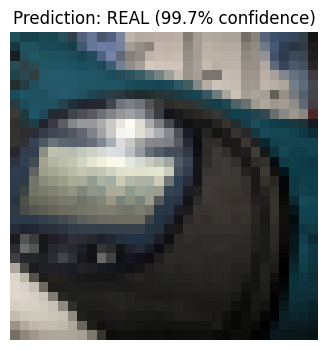

In [ ]:
from google.colab import files

uploaded = files.upload()  # pick any image from your computer
image_path = list(uploaded.keys())[0]

label, confidence, img = predict_image(image_path, model_dual, device)

plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.title(f"Prediction: {label} ({confidence*100:.1f}% confidence)")
plt.axis('off')
plt.show()